In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

print("Ambiente configurado com sucesso!")
print(f"Versão do pandas: {pd.__version__}")
print(f"Versão do NumPy: {np.__version__}")

Ambiente configurado com sucesso!
Versão do pandas: 3.0.6
Versão do NumPy: 2.4.6


In [2]:
# Caminho para a pasta que contém os dados brutos
DATA_DIR = Path("../data/raw")

# Caminhos das quatro bases
arquivos = {
    "queimadas": DATA_DIR / "queimadas_2024_2025.csv",
    "mapbiomas": DATA_DIR / "MapBiomas.csv",
    "estacoes": DATA_DIR / "BDMEP-estacao.csv",
    "meteorologia": DATA_DIR / "BDMEP-2025.csv"
}

# Verificar se todos os arquivos foram encontrados
for nome, caminho in arquivos.items():
    print(f"{nome:15} | Existe: {caminho.exists()} | {caminho.name}")

queimadas       | Existe: True | queimadas_2024_2025.csv
mapbiomas       | Existe: True | MapBiomas.csv
estacoes        | Existe: True | BDMEP-estacao.csv
meteorologia    | Existe: True | BDMEP-2025.csv


# Análise e Compreensão dos Dados

## Projeto Final — Previsão de Risco de Incêndios no Brasil

Neste notebook, será realizada a análise inicial das quatro bases de dados utilizadas no projeto.

O objetivo desta etapa é compreender a estrutura dos dados, identificar as principais variáveis, verificar tipos de dados, valores ausentes, duplicatas e possíveis relações entre as bases antes das etapas de tratamento e modelagem.

### Bases utilizadas

1. **Queimadas 2024–2025** — registros de focos de queimadas.
2. **MapBiomas** — informações territoriais e ambientais.
3. **BDMEP Estações** — informações das estações meteorológicas.
4. **BDMEP 2025** — medições meteorológicas.

## Inspeção inicial das bases

Nesta etapa, será realizada uma leitura de uma pequena amostra de cada base para identificar sua estrutura, colunas e formato antes do carregamento completo dos dados.

In [3]:
# Leitura inicial de apenas 5 linhas de cada base
# Isso evita carregar os arquivos grandes completamente na memória.

amostras = {}

for nome, caminho in arquivos.items():
    print(f"\n{'=' * 60}")
    print(f"BASE: {nome.upper()}")
    print(f"{'=' * 60}")

    try:
        df_sample = pd.read_csv(caminho, nrows=5)
        amostras[nome] = df_sample

        print(f"Quantidade de colunas: {df_sample.shape[1]}")
        print("\nColunas:")
        print(df_sample.columns.tolist())

        display(df_sample)

    except Exception as e:
        print(f"Erro ao ler {nome}: {e}")


BASE: QUEIMADAS
Quantidade de colunas: 1

Colunas:
['ano;mes;data_hora;bioma;sigla_uf;sigla_uf_nome;id_municipio;id_municipio_nome;latitude;longitude;satelite;dias_sem_chuva;precipitacao;risco_fogo;potencia_radiativa_fogo']


,ano;mes;data_hora;bioma;sigla_uf;sigla_uf_nome;id_municipio;id_municipio_nome;latitude;longitude;satelite;dias_sem_chuva;precipitacao;risco_fogo;potencia_radiativa_fogo
0,2024;9;2024-09-13 04:29:00;Mata Atlântica;MG;Minas Gerais;3166907;Serrania;-21.56454;-46.03047;NPP-375D;19.0;0.0;1.0;7.3
1,2024;9;2024-09-13 04:29:00;Mata Atlântica;ES;Espírito Santo;3202652;Irupi;-20.27151;-41.69187;NPP-375D;34.0;0.0;1.0;3.8
2,2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3300308;Barra do Piraí;-22.42786;-43.81413;NPP-375D;18.0;0.0;1.0;2.5
3,2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3303708;Paraíba do Sul;-22.18328;-43.35031;NPP-375D;18.0;0.0;1.0;26.5
4,2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3303906;Petrópolis;-22.53255;-43.13242;NPP-375D;-999.0;0.0;1.0;2.0



BASE: MAPBIOMAS
Quantidade de colunas: 7

Colunas:
['ano', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'id_classe', 'area']


,ano,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,id_classe,area
0,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,3,5107.484730
1,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,4,270.661602
2,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,11,7.426764
3,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,12,937.381233
4,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,15,613.888604



BASE: ESTACOES
Quantidade de colunas: 8

Colunas:
['id_municipio', 'id_municipio_nome', 'id_estacao', 'estacao', 'data_fundacao', 'latitude', 'longitude', 'altitude']


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
0,5300108,Brasília,A001,Brasilia,2000-05-07,-15.789444,-47.925833,1160.96
1,5300108,Brasília,A042,Brazlandia,2017-07-19,-15.599722,-48.131111,1143.00
2,5300108,Brasília,A045,Aguas Emendadas,2008-10-03,-15.596491,-47.625801,1030.36
3,5300108,Brasília,A046,Gama (Ponte Alta),2014-10-01,-15.935278,-48.137500,990.00
4,5300108,Brasília,A047,Paranoa (Coopa-Df),2017-02-07,-16.012222,-47.557417,1043.00



BASE: METEOROLOGIA
Quantidade de colunas: 21

Colunas:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,temperatura_orvalho_hora,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,2025,2025-05-29,13:00:00,A316,0.0,997.6,997.9,997.5,2523.7,30.7,16.0,31.1,28.8,18.5,15.9,53.0,41.0,41.0,106.0,9.1,4.2
1,2025,2025-01-21,16:00:00,A867,0.0,1007.7,1008.4,1007.7,3896.8,32.6,17.6,32.8,31.6,18.6,14.8,46.0,34.0,41.0,256.0,8.8,4.5
2,2025,2025-05-14,18:00:00,A366,0.0,958.9,959.3,958.7,2227.9,30.3,11.8,31.2,29.5,13.7,11.8,36.0,31.0,32.0,119.0,11.7,5.5
3,2025,2025-05-27,16:00:00,A849,0.0,971.3,972.2,971.3,2279.0,29.8,15.3,29.8,27.9,15.4,14.5,45.0,41.0,41.0,NaN,10.3,5.5
4,2025,2025-04-01,19:00:00,A349,0.0,959.8,959.9,959.7,1831.7,33.6,16.2,34.3,33.3,16.3,15.4,35.0,33.0,35.0,165.0,10.7,5.2


In [4]:
# Inspeção das bases usando detecção automática do separador

amostras = {}

for nome, caminho in arquivos.items():
    print(f"\n{'=' * 60}")
    print(f"BASE: {nome.upper()}")
    print(f"{'=' * 60}")

    try:
        # sep=None tenta detectar automaticamente o separador
        df_sample = pd.read_csv(
            caminho,
            nrows=5,
            sep=None,
            engine="python"
        )

        amostras[nome] = df_sample

        print(f"Quantidade de colunas: {df_sample.shape[1]}")
        print("\nColunas:")
        print(df_sample.columns.tolist())

        display(df_sample)

    except Exception as e:
        print(f"Erro ao ler {nome}: {e}")


BASE: QUEIMADAS
Quantidade de colunas: 15

Colunas:
['\ufeffano', 'mes', 'data_hora', 'bioma', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'latitude', 'longitude', 'satelite', 'dias_sem_chuva', 'precipitacao', 'risco_fogo', 'potencia_radiativa_fogo']


,﻿ano,mes,data_hora,bioma,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,latitude,longitude,satelite,dias_sem_chuva,precipitacao,risco_fogo,potencia_radiativa_fogo
0,2024,9,2024-09-13 04:29:00,Mata Atlântica,MG,Minas Gerais,3166907,Serrania,-21.56454,-46.03047,NPP-375D,19.0,0.0,1.0,7.3
1,2024,9,2024-09-13 04:29:00,Mata Atlântica,ES,Espírito Santo,3202652,Irupi,-20.27151,-41.69187,NPP-375D,34.0,0.0,1.0,3.8
2,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3300308,Barra do Piraí,-22.42786,-43.81413,NPP-375D,18.0,0.0,1.0,2.5
3,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303708,Paraíba do Sul,-22.18328,-43.35031,NPP-375D,18.0,0.0,1.0,26.5
4,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303906,Petrópolis,-22.53255,-43.13242,NPP-375D,-999.0,0.0,1.0,2.0



BASE: MAPBIOMAS
Quantidade de colunas: 7

Colunas:
['ano', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'id_classe', 'area']


,ano,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,id_classe,area
0,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,3,5107.484730
1,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,4,270.661602
2,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,11,7.426764
3,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,12,937.381233
4,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,15,613.888604



BASE: ESTACOES
Quantidade de colunas: 8

Colunas:
['id_municipio', 'id_municipio_nome', 'id_estacao', 'estacao', 'data_fundacao', 'latitude', 'longitude', 'altitude']


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
0,5300108,Brasília,A001,Brasilia,2000-05-07,-15.789444,-47.925833,1160.96
1,5300108,Brasília,A042,Brazlandia,2017-07-19,-15.599722,-48.131111,1143.00
2,5300108,Brasília,A045,Aguas Emendadas,2008-10-03,-15.596491,-47.625801,1030.36
3,5300108,Brasília,A046,Gama (Ponte Alta),2014-10-01,-15.935278,-48.137500,990.00
4,5300108,Brasília,A047,Paranoa (Coopa-Df),2017-02-07,-16.012222,-47.557417,1043.00



BASE: METEOROLOGIA
Quantidade de colunas: 21

Colunas:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,temperatura_orvalho_hora,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,2025,2025-05-29,13:00:00,A316,0.0,997.6,997.9,997.5,2523.7,30.7,16.0,31.1,28.8,18.5,15.9,53.0,41.0,41.0,106.0,9.1,4.2
1,2025,2025-01-21,16:00:00,A867,0.0,1007.7,1008.4,1007.7,3896.8,32.6,17.6,32.8,31.6,18.6,14.8,46.0,34.0,41.0,256.0,8.8,4.5
2,2025,2025-05-14,18:00:00,A366,0.0,958.9,959.3,958.7,2227.9,30.3,11.8,31.2,29.5,13.7,11.8,36.0,31.0,32.0,119.0,11.7,5.5
3,2025,2025-05-27,16:00:00,A849,0.0,971.3,972.2,971.3,2279.0,29.8,15.3,29.8,27.9,15.4,14.5,45.0,41.0,41.0,NaN,10.3,5.5
4,2025,2025-04-01,19:00:00,A349,0.0,959.8,959.9,959.7,1831.7,33.6,16.2,34.3,33.3,16.3,15.4,35.0,33.0,35.0,165.0,10.7,5.2


In [5]:
# Verificar tamanho das bases sem carregar tudo na memória

for nome, caminho in arquivos.items():
    print(f"\n{'=' * 50}")
    print(f"BASE: {nome.upper()}")

    try:
        # Detectar estrutura usando apenas uma pequena amostra
        amostra = pd.read_csv(
            caminho,
            sep=None,
            engine="python",
            nrows=100
        )

        # Contar linhas diretamente no arquivo
        with open(caminho, "r", encoding="utf-8", errors="ignore") as f:
            total_linhas = sum(1 for _ in f) - 1

        print(f"Linhas: {total_linhas:,}")
        print(f"Colunas: {amostra.shape[1]}")

    except Exception as e:
        print(f"Erro: {e}")


BASE: QUEIMADAS
Linhas: 8,226,944
Colunas: 15

BASE: MAPBIOMAS
Linhas: 2,286,656
Colunas: 7

BASE: ESTACOES
Linhas: 612
Colunas: 8

BASE: METEOROLOGIA
Linhas: 4,891,176
Colunas: 21


In [6]:
# Análise inicial em chunks das bases grandes

for nome, caminho in arquivos.items():
    print(f"\n{'=' * 60}")
    print(f"BASE: {nome.upper()}")
    print("=" * 60)

    try:
        # Amostra de até 100.000 registros
        df = pd.read_csv(
            caminho,
            sep=None,
            engine="python",
            nrows=100_000
        )

        print(f"\nDimensão da amostra: {df.shape}")

        print("\nTipos de dados:")
        print(df.dtypes)

        print("\nValores ausentes:")
        ausentes = df.isnull().sum()
        print(ausentes[ausentes > 0].sort_values(ascending=False))

        print(f"\nDuplicatas na amostra: {df.duplicated().sum():,}")

    except Exception as e:
        print(f"Erro ao analisar {nome}: {e}")


BASE: QUEIMADAS

Dimensão da amostra: (100000, 15)

Tipos de dados:
﻿ano                         int64
mes                          int64
data_hora                      str
bioma                          str
sigla_uf                       str
sigla_uf_nome                  str
id_municipio                 int64
id_municipio_nome              str
latitude                   float64
longitude                  float64
satelite                       str
dias_sem_chuva             float64
precipitacao               float64
risco_fogo                 float64
potencia_radiativa_fogo    float64
dtype: object

Valores ausentes:
potencia_radiativa_fogo    3804
dias_sem_chuva             2670
precipitacao               2670
risco_fogo                 2670
dtype: int64

Duplicatas na amostra: 0

BASE: MAPBIOMAS

Dimensão da amostra: (100000, 7)

Tipos de dados:
ano                    int64
sigla_uf                 str
sigla_uf_nome            str
id_municipio           int64
id_municipio_nome     

In [7]:
# Valores ausentes - QUEIMADAS

df = pd.read_csv(
    arquivos["queimadas"],
    sep=None,
    engine="python",
    nrows=100_000
)

print("VALORES AUSENTES - QUEIMADAS")
print("=" * 40)

ausentes = df.isna().sum()

print(ausentes)

VALORES AUSENTES - QUEIMADAS
﻿ano                          0
mes                           0
data_hora                     0
bioma                         0
sigla_uf                      0
sigla_uf_nome                 0
id_municipio                  0
id_municipio_nome             0
latitude                      0
longitude                     0
satelite                      0
dias_sem_chuva             2670
precipitacao               2670
risco_fogo                 2670
potencia_radiativa_fogo    3804
dtype: int64


In [8]:
# Valores ausentes - MAPBIOMAS

df_mapbiomas = pd.read_csv(
    arquivos["mapbiomas"],
    sep=None,
    engine="python",
    nrows=100_000
)

print("VALORES AUSENTES - MAPBIOMAS")
print("=" * 40)

print(df_mapbiomas.isna().sum())

print("\nDuplicatas:", df_mapbiomas.duplicated().sum())

VALORES AUSENTES - MAPBIOMAS
ano                  0
sigla_uf             0
sigla_uf_nome        0
id_municipio         0
id_municipio_nome    0
id_classe            0
area                 0
dtype: int64

Duplicatas: 0


In [9]:
# Análise de valores ausentes e duplicatas - ESTAÇÕES

df_estacoes = pd.read_csv(
    arquivos["estacoes"],
    sep=None,
    engine="python"
)

print("VALORES AUSENTES - ESTAÇÕES")
print("=" * 40)

print(df_estacoes.isna().sum())

print("\nDuplicatas:", df_estacoes.duplicated().sum())
print("\nDimensão:", df_estacoes.shape)

VALORES AUSENTES - ESTAÇÕES
id_municipio          2
id_municipio_nome     2
id_estacao            0
estacao               0
data_fundacao         0
latitude              0
longitude             0
altitude             17
dtype: int64

Duplicatas: 0

Dimensão: (612, 8)


In [10]:
# Valores ausentes e duplicatas - METEOROLOGIA

df_meteorologia = pd.read_csv(
    arquivos["meteorologia"],
    sep=None,
    engine="python",
    nrows=100_000
)

print("VALORES AUSENTES - METEOROLOGIA")
print("=" * 40)

print(df_meteorologia.isna().sum())

print("\nDuplicatas:", df_meteorologia.duplicated().sum())
print("\nDimensão da amostra:", df_meteorologia.shape)

VALORES AUSENTES - METEOROLOGIA
ano                             0
data                            0
hora                            0
id_estacao                      0
precipitacao_total          53064
pressao_atm_hora            43333
pressao_atm_max             43419
pressao_atm_min             43426
radiacao_global             69572
temperatura_bulbo_hora      43929
temperatura_orvalho_hora    49196
temperatura_max             44081
temperatura_min             44082
temperatura_orvalho_max     49385
temperatura_orvalho_min     49404
umidade_rel_max             49057
umidade_rel_min             49027
umidade_rel_hora            48890
vento_direcao               52973
vento_rajada_max            54166
vento_velocidade            54073
dtype: int64

Duplicatas: 1573

Dimensão da amostra: (100000, 21)


## Análise Exploratória Complementar

Nesta seção, a análise exploratória é aprofundada com o objetivo de investigar relações entre as variáveis numéricas, identificar possíveis valores extremos e avaliar formalmente uma hipótese relacionada ao risco de fogo.

As análises realizadas incluem:

1. visualização da distribuição das principais variáveis;
2. investigação de possíveis outliers;
3. análise da correlação entre variáveis numéricas;
4. formulação e teste de uma hipótese estatística com definição explícita de H0 e H1.

Essas análises complementam a inspeção inicial das bases e ajudam a compreender melhor os padrões presentes nos dados antes da etapa de modelagem.

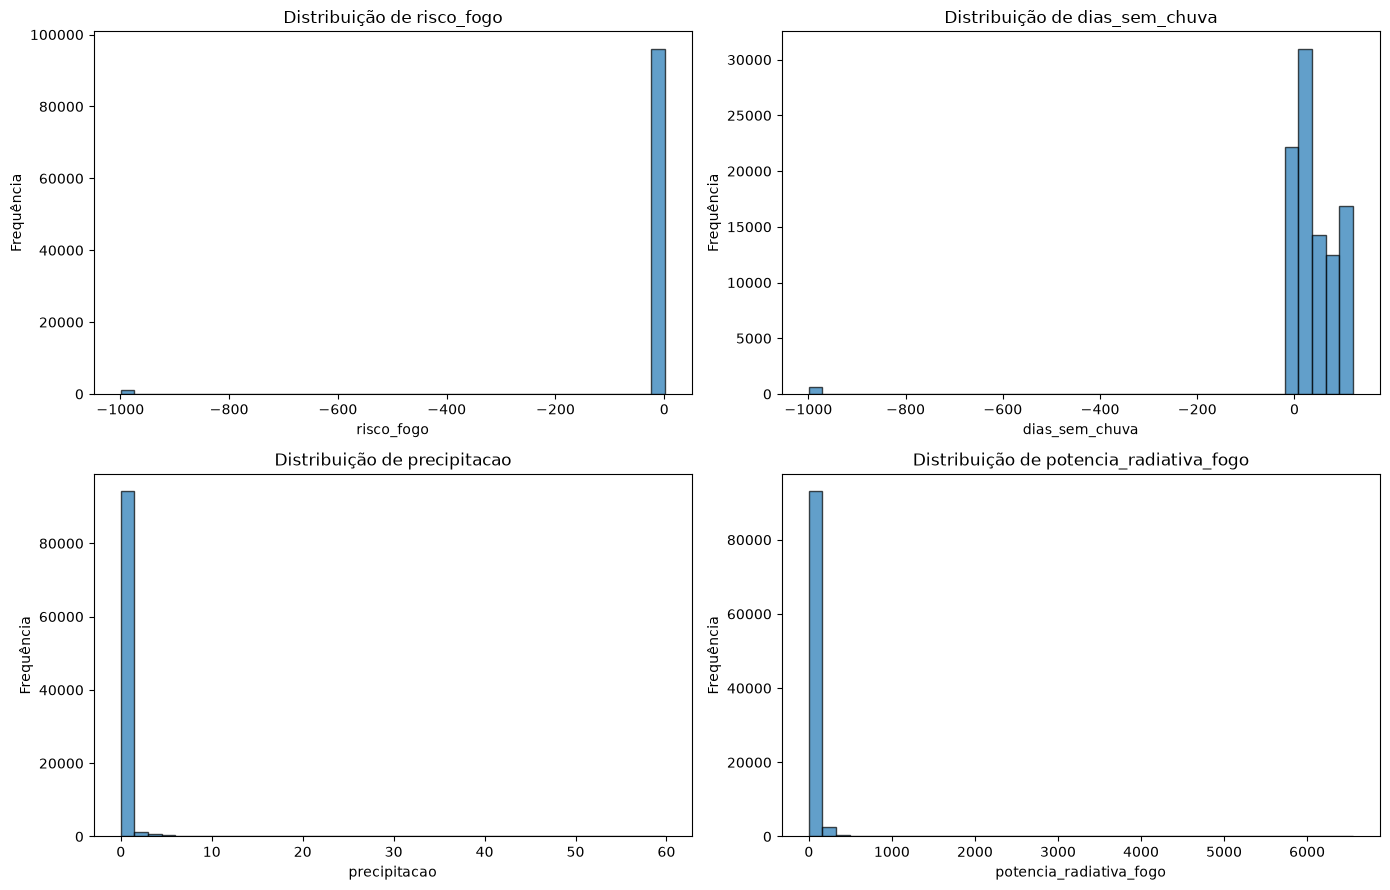

In [11]:
import matplotlib.pyplot as plt

# ============================================================
# DISTRIBUIÇÃO DAS PRINCIPAIS VARIÁVEIS DE QUEIMADAS
# ============================================================

variaveis_eda = [
    "risco_fogo",
    "dias_sem_chuva",
    "precipitacao",
    "potencia_radiativa_fogo"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, coluna in zip(axes.flatten(), variaveis_eda):
    dados_plot = df[coluna].dropna()

    ax.hist(
        dados_plot,
        bins=40,
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribuição de {coluna}")
    ax.set_xlabel(coluna)
    ax.set_ylabel("Frequência")

plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# INVESTIGAÇÃO DE VALORES EXTREMOS E POSSÍVEIS OUTLIERS
# ============================================================

variaveis_outliers = [
    "risco_fogo",
    "dias_sem_chuva",
    "precipitacao",
    "potencia_radiativa_fogo"
]

for coluna in variaveis_outliers:
    serie = df[coluna].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = serie[
        (serie < limite_inferior) |
        (serie > limite_superior)
    ]

    print("=" * 60)
    print(f"VARIÁVEL: {coluna}")
    print(f"Mínimo observado: {serie.min():.2f}")
    print(f"Q1: {q1:.2f}")
    print(f"Mediana: {serie.median():.2f}")
    print(f"Q3: {q3:.2f}")
    print(f"Máximo observado: {serie.max():.2f}")
    print(f"Limite inferior (IQR): {limite_inferior:.2f}")
    print(f"Limite superior (IQR): {limite_superior:.2f}")
    print(f"Valores fora dos limites do IQR: {len(outliers):,}")
    print(f"Percentual: {len(outliers) / len(serie) * 100:.2f}%")
    print()

VARIÁVEL: risco_fogo
Mínimo observado: -999.00
Q1: 0.94
Mediana: 1.00
Q3: 1.00
Máximo observado: 1.00
Limite inferior (IQR): 0.85
Limite superior (IQR): 1.09
Valores fora dos limites do IQR: 19,196
Percentual: 19.72%

VARIÁVEL: dias_sem_chuva
Mínimo observado: -999.00
Q1: 9.00
Mediana: 30.00
Q3: 76.00
Máximo observado: 120.00
Limite inferior (IQR): -91.50
Limite superior (IQR): 176.50
Valores fora dos limites do IQR: 659
Percentual: 0.68%

VARIÁVEL: precipitacao
Mínimo observado: 0.00
Q1: 0.00
Mediana: 0.00
Q3: 0.00
Máximo observado: 59.82
Limite inferior (IQR): 0.00
Limite superior (IQR): 0.00
Valores fora dos limites do IQR: 9,262
Percentual: 9.52%

VARIÁVEL: potencia_radiativa_fogo
Mínimo observado: -0.30
Q1: 3.30
Mediana: 8.60
Q3: 37.80
Máximo observado: 6550.40
Limite inferior (IQR): -48.45
Limite superior (IQR): 89.55
Valores fora dos limites do IQR: 10,739
Percentual: 11.16%



### Interpretação dos valores extremos

A análise pelo intervalo interquartil (IQR) identificou uma quantidade relevante de observações fora dos limites estatísticos em algumas variáveis. Entretanto, esses valores não devem ser automaticamente removidos, pois um valor estatisticamente extremo pode representar uma condição ambiental real.

Um resultado particularmente importante foi a presença do valor **-999** em variáveis como `risco_fogo` e `dias_sem_chuva`. Esses valores não representam condições físicas plausíveis e são utilizados como códigos para informações inválidas ou ausentes. Portanto, devem ser tratados separadamente durante a preparação dos dados.

Para `risco_fogo`, a presença desses códigos também influencia fortemente a distribuição observada e a quantidade de valores classificados como extremos pelo método do IQR.

Por outro lado, valores elevados de `precipitacao` e `potencia_radiativa_fogo` podem representar eventos meteorológicos ou focos de calor realmente intensos. Por esse motivo, o critério do IQR é utilizado aqui principalmente como ferramenta de diagnóstico, e não como regra automática para exclusão de observações.

Essa análise reforça a importância de diferenciar **valores inválidos codificados na base** de **eventos extremos potencialmente legítimos** antes da modelagem.

,latitude,longitude,dias_sem_chuva,precipitacao,risco_fogo,potencia_radiativa_fogo
latitude,1.000,0.029,-0.255,0.057,-0.164,-0.013
longitude,0.029,1.000,0.042,-0.067,-0.047,-0.051
dias_sem_chuva,-0.255,0.042,1.000,-0.119,0.371,0.044
precipitacao,0.057,-0.067,-0.119,1.000,-0.375,-0.017
risco_fogo,-0.164,-0.047,0.371,-0.375,1.000,0.040
potencia_radiativa_fogo,-0.013,-0.051,0.044,-0.017,0.040,1.000


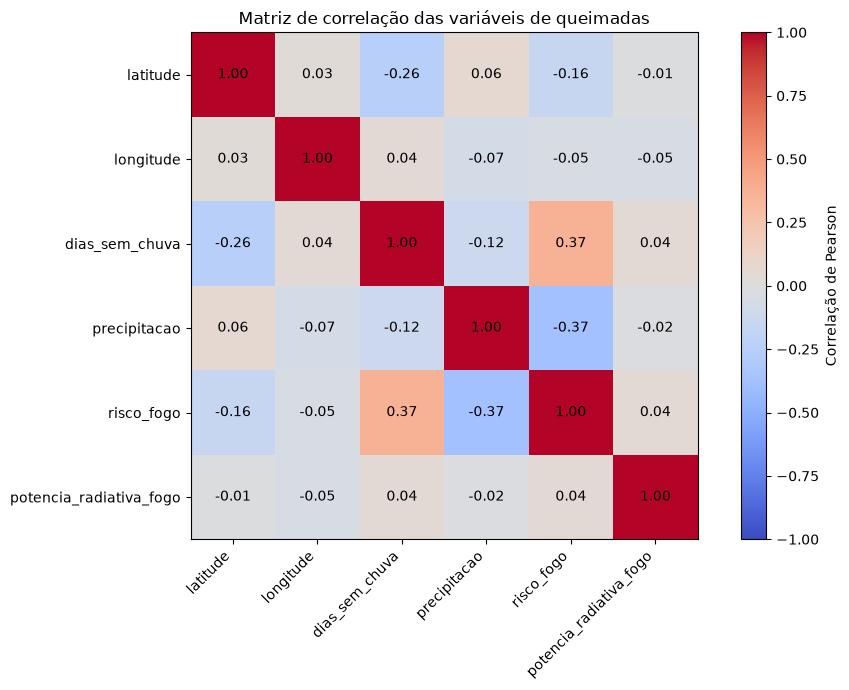

In [13]:
# ============================================================
# MATRIZ DE CORRELAÇÃO — VARIÁVEIS DE QUEIMADAS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

variaveis_correlacao = [
    "latitude",
    "longitude",
    "dias_sem_chuva",
    "precipitacao",
    "risco_fogo",
    "potencia_radiativa_fogo"
]

# Selecionar apenas as variáveis numéricas de interesse
df_correlacao = df[variaveis_correlacao].copy()

# Substituir códigos inválidos -999 por NaN
df_correlacao = df_correlacao.replace(-999, np.nan)

# Calcular matriz de correlação de Pearson
matriz_correlacao = df_correlacao.corr()

# Exibir valores
display(matriz_correlacao.round(3))

# Visualização
fig, ax = plt.subplots(figsize=(10, 7))

imagem = ax.imshow(
    matriz_correlacao,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(variaveis_correlacao)))
ax.set_yticks(range(len(variaveis_correlacao)))

ax.set_xticklabels(
    variaveis_correlacao,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(variaveis_correlacao)

# Mostrar os coeficientes dentro da matriz
for i in range(len(variaveis_correlacao)):
    for j in range(len(variaveis_correlacao)):
        valor = matriz_correlacao.iloc[i, j]
        ax.text(
            j,
            i,
            f"{valor:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(imagem, ax=ax, label="Correlação de Pearson")

ax.set_title("Matriz de correlação das variáveis de queimadas")

plt.tight_layout()
plt.show()

### Interpretação da matriz de correlação

A matriz de correlação mostra que as relações lineares mais relevantes com `risco_fogo` aparecem em `dias_sem_chuva` e `precipitacao`.

A variável `dias_sem_chuva` apresentou correlação positiva de aproximadamente **0,371** com `risco_fogo`, indicando que períodos mais prolongados sem chuva tendem a estar associados a valores maiores do indicador de risco.

Por outro lado, `precipitacao` apresentou correlação negativa de aproximadamente **-0,375** com `risco_fogo`, sugerindo que maiores níveis de precipitação tendem a estar associados a menores valores de risco.

A latitude apresentou uma relação negativa mais fraca, de aproximadamente **-0,164**, enquanto longitude e `potencia_radiativa_fogo` apresentaram correlações lineares próximas de zero com `risco_fogo`.

É importante destacar que essas correlações representam apenas associações lineares entre as variáveis e **não devem ser interpretadas como relações causais**. Além disso, relações fracas na correlação de Pearson não significam necessariamente ausência de informação útil para modelos capazes de capturar padrões não lineares.

### Teste de hipótese: precipitação e risco de fogo

A análise de correlação indicou uma associação negativa entre `precipitacao` e `risco_fogo`. Para investigar essa relação de forma estatística, será realizado um teste de hipótese comparando o risco de fogo entre observações sem precipitação e observações com precipitação.

As hipóteses são definidas como:

- **H0 (hipótese nula):** não existe diferença estatisticamente significativa no risco de fogo entre observações sem precipitação e observações com precipitação.
- **H1 (hipótese alternativa):** existe diferença estatisticamente significativa no risco de fogo entre observações sem precipitação e observações com precipitação.

Será adotado um nível de significância de **5% (`α = 0,05`)**.

Como a distribuição de `risco_fogo` é fortemente concentrada e apresenta características que podem violar a suposição de normalidade, será utilizado o **teste não paramétrico de Mann–Whitney U** para comparar os dois grupos.

Antes do teste, os códigos inválidos `-999` serão removidos da análise.

In [14]:
# ============================================================
# TESTE DE HIPÓTESE — PRECIPITAÇÃO E RISCO DE FOGO
# Mann–Whitney U
# ============================================================

import numpy as np
from scipy.stats import mannwhitneyu

# Selecionar apenas as variáveis necessárias
df_teste = df[["precipitacao", "risco_fogo"]].copy()

# Remover códigos inválidos (-999) e valores ausentes
df_teste = df_teste.replace(-999, np.nan).dropna()

# Separar os grupos
grupo_sem_chuva = df_teste.loc[
    df_teste["precipitacao"] == 0,
    "risco_fogo"
]

grupo_com_chuva = df_teste.loc[
    df_teste["precipitacao"] > 0,
    "risco_fogo"
]

# Teste de Mann–Whitney U
estatistica_u, p_valor = mannwhitneyu(
    grupo_sem_chuva,
    grupo_com_chuva,
    alternative="two-sided"
)

alpha = 0.05

print("=== TESTE DE HIPÓTESE: PRECIPITAÇÃO E RISCO DE FOGO ===")
print()
print(f"Observações sem chuva: {len(grupo_sem_chuva):,}")
print(f"Observações com chuva: {len(grupo_com_chuva):,}")
print()
print(f"Mediana do risco — sem chuva: {grupo_sem_chuva.median():.4f}")
print(f"Mediana do risco — com chuva: {grupo_com_chuva.median():.4f}")
print()
print(f"Estatística U: {estatistica_u:,.2f}")
print(f"p-valor: {p_valor:.6g}")
print(f"Nível de significância (alpha): {alpha}")
print()

if p_valor < alpha:
    print("Resultado: rejeitamos H0.")
    print(
        "Há evidência estatística de diferença no risco de fogo "
        "entre observações sem chuva e com chuva."
    )
else:
    print("Resultado: não rejeitamos H0.")
    print(
        "Não há evidência estatística suficiente de diferença "
        "no risco de fogo entre observações sem chuva e com chuva."
    )

=== TESTE DE HIPÓTESE: PRECIPITAÇÃO E RISCO DE FOGO ===

Observações sem chuva: 86,997
Observações com chuva: 9,109

Mediana do risco — sem chuva: 1.0000
Mediana do risco — com chuva: 0.7600

Estatística U: 603,436,681.50
p-valor: 0
Nível de significância (alpha): 0.05

Resultado: rejeitamos H0.
Há evidência estatística de diferença no risco de fogo entre observações sem chuva e com chuva.


### Interpretação do teste de hipótese

O teste de Mann–Whitney U comparou **86.997 observações sem precipitação** com **9.109 observações com precipitação**.

A mediana de `risco_fogo` foi de **1,00 nas observações sem chuva** e de **0,76 nas observações com chuva**.

O teste produziu um p-valor extremamente pequeno, inferior ao nível de significância adotado de **0,05**. Portanto, **rejeitamos a hipótese nula (H0)**.

Há evidência estatística de que a distribuição do risco de fogo difere entre observações sem precipitação e observações com precipitação na amostra analisada. Além disso, os valores observados indicam risco de fogo mais elevado no grupo sem precipitação.

Esse resultado é consistente com a correlação negativa observada anteriormente entre `precipitacao` e `risco_fogo`. Entretanto, o teste identifica uma associação estatística e **não demonstra uma relação causal** entre precipitação e risco de fogo.

Também é importante considerar que o grande tamanho da amostra aumenta o poder estatístico do teste. Por isso, além da significância estatística, deve-se observar a magnitude da diferença entre os grupos e sua relevância prática.

## Conclusão

Neste projeto, construí uma pipeline de Machine Learning para classificar o risco de incêndio no Brasil em três níveis: **Baixo, Médio e Alto**. Para isso, integrei informações de diferentes fontes, combinando registros de queimadas, dados meteorológicos do INMET, informações geográficas e dados de cobertura e uso da terra do MapBiomas.

Uma das partes mais desafiadoras foi a preparação dos dados. As bases apresentavam diferentes níveis de granularidade, períodos de cobertura distintos e valores ausentes. Para integrar os dados meteorológicos aos registros de queimadas, associei cada município à estação meteorológica disponível mais próxima. Essa decisão permitiu ampliar significativamente a cobertura meteorológica, embora também introduza uma limitação para municípios localizados muito longe de uma estação.

Também foi necessário tratar cuidadosamente a variável alvo. O risco diário foi construído a partir do valor máximo de `risco_fogo` observado para cada município e dia, representando uma abordagem mais conservadora, na qual prevalece o maior nível de risco registrado naquele período.

Na etapa de modelagem, utilizei um Dummy Classifier como baseline, Regressão Logística e diferentes configurações de Random Forest. Como a variável alvo apresenta forte desbalanceamento, a avaliação não foi baseada apenas em acurácia. Foram consideradas principalmente as métricas **Balanced Accuracy** e **F1 Macro**, além dos resultados individuais de cada classe.

Entre os modelos avaliados, as duas configurações de Random Forest apresentaram os melhores resultados nas principais métricas consideradas. Na divisão aleatória estratificada, o Random Forest original alcançou aproximadamente **83,67% de acurácia, 73,92% de Balanced Accuracy e F1 Macro de 0,7040**. A configuração ajustada alcançou acurácia ligeiramente superior, de **84,31%**, e F1 Macro de **0,7050**, mas apresentou Balanced Accuracy menor e redução no recall da classe Médio. Por esse motivo, mantive o Random Forest original como principal referência para interpretação.

A validação temporal trouxe uma perspectiva importante. Ao treinar o modelo com dados anteriores e avaliá-lo em um período futuro, a acurácia caiu para **69,99%**, a Balanced Accuracy para **55,40%** e o F1 Macro para **0,5516**. As classes Baixo e Alto continuaram apresentando desempenho razoável, enquanto a classe Médio foi significativamente mais difícil de identificar. Isso mostra que uma avaliação aleatória pode produzir uma visão mais otimista do desempenho e que os padrões associados ao risco de incêndio podem mudar ao longo do tempo.

A análise de importância das variáveis mostrou forte participação de fatores temporais, principalmente `dia_do_ano` e `mes`, seguidos por localização geográfica, umidade, temperatura e diferentes classes de cobertura do solo. Esses resultados indicam que o modelo utiliza uma combinação de sazonalidade, localização, condições meteorológicas e características ambientais para realizar suas classificações.

### Limitações

É importante destacar que a base de queimadas utilizada contém registros de eventos detectados. Portanto, o modelo desenvolvido neste projeto **não estima diretamente a probabilidade de ocorrer ou não um novo incêndio em qualquer município brasileiro**. A tarefa realizada consiste em prever a **categoria de risco de fogo derivada do indicador `risco_fogo` do INPE para observações município-dia presentes na base de queimadas**.

Essa distinção é importante porque um modelo de previsão da ocorrência de novos incêndios exigiria também exemplos de municípios e dias sem registros de focos, permitindo construir explicitamente uma classe de não ocorrência.

Outra limitação é que os dados do MapBiomas utilizados correspondem ao ano de 2021 e foram tratados como características ambientais estáticas para o período de 2024–2025. Além disso, a associação meteorológica utiliza a estação disponível mais próxima e, em algumas regiões com baixa densidade de estações, essa distância pode ser elevada.

Os valores meteorológicos ausentes foram tratados dentro da pipeline de Machine Learning utilizando a mediana calculada somente sobre os dados de treinamento, reduzindo o risco de vazamento de informações entre treino e teste.

Finalmente, as importâncias produzidas pelo Random Forest indicam quais variáveis foram mais utilizadas pelo modelo para realizar suas decisões, mas **não representam relações causais**.

### Próximos passos

Como evolução deste trabalho, seria interessante construir uma base completa de municípios e dias, incluindo períodos sem focos de incêndio, permitindo transformar o problema em uma previsão direta da ocorrência de queimadas. Também seria possível incorporar dados mais recentes de cobertura do solo, testar estratégias específicas para melhorar a identificação da classe Médio e utilizar validação temporal contínua para acompanhar mudanças nos padrões ambientais.

Para uma aplicação operacional, o modelo também deveria ser atualizado periodicamente com novos dados meteorológicos e ambientais, além de ter seu desempenho monitorado ao longo do tempo.

## Conclusões da inspeção inicial

A inspeção inicial mostrou que as quatro bases possuem características bastante diferentes e, por isso, precisarão de estratégias específicas de preparação.

### Base de queimadas
A base de queimadas é a principal fonte de informação sobre as ocorrências de fogo. Ela possui mais de 8 milhões de registros e contém informações temporais, territoriais e indicadores relacionados às condições de fogo.

Na amostra analisada, foram identificados valores ausentes principalmente nas variáveis `dias_sem_chuva`, `precipitacao`, `risco_fogo` e `potencia_radiativa_fogo`. Não foram encontrados registros duplicados na base de queimadas, portanto não foi necessário realizar remoção de duplicatas nessa base durante a etapa de tratamento.

### MapBiomas
A base do MapBiomas apresenta informações territoriais e de classes de uso/cobertura do solo por município. Não foram encontrados valores ausentes nem registros duplicados na análise realizada.

### Estações meteorológicas
A base de estações contém 612 registros. Foram identificados poucos valores ausentes: 2 em `id_municipio` e `id_municipio_nome`, além de 17 em `altitude`. Não foram encontrados registros duplicados.

### Dados meteorológicos
A base meteorológica possui aproximadamente 4,9 milhões de registros e apresenta uma quantidade significativa de valores ausentes em diversas variáveis meteorológicas, como precipitação, pressão atmosférica, radiação, temperatura, umidade e vento.

Por causa da elevada proporção de valores ausentes em algumas dessas variáveis, não será adequado simplesmente remover todas as linhas incompletas. Será necessário avaliar quais variáveis são realmente importantes para a previsão do risco de incêndio e definir uma estratégia de tratamento adequada.

### Próximos passos

A próxima etapa será dedicada à preparação dos dados, incluindo:

- análise das datas e períodos disponíveis em cada base;
- identificação e tratamento de duplicatas;
- análise dos valores ausentes;
- seleção das variáveis relevantes;
- padronização dos identificadores territoriais e temporais;
- definição da estratégia de integração entre as quatro bases.

Essa etapa será especialmente importante porque as bases possuem granularidades diferentes e não devem ser combinadas diretamente sem antes definir corretamente as chaves de integração.